# Chapter 2 · Measures: interactive demos

Companion to Chapter 2 of the notes
[*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/02-measures.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.measures import (DiscreteMeasure, FinCofin, bonferroni_sums, counting_measure,
                                dirac, expected_count, liminf_limsup_periodic, mu_two_power,
                                no_match_probability, occurrence_times, occurrence_times_exact,
                                prob_no_event)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN = "#1BAF7A"

## 1. Measures on finite and countable sets

`DiscreteMeasure` is Example 3 of the notes: $\mu(A)=\sum_{i\in A}f(i)$. The Dirac and counting measures are special
cases. Subsets of $\mathbb N$ that are finite or cofinite are `FinCofin` objects, so we can also evaluate the set
function of the worked exercise, $\mu(A)=\sum_{n\in A}2^{-n}$ on finite sets and $+\infty$ on infinite ones. It is
additive, but $\mathbb N=\bigcup_n\{n\}$ has measure $+\infty$ while the singletons add up to $2$.

In [2]:
N = FinCofin.naturals()
delta = dirac(3)
count = counting_measure()
print("delta_3({1,2,3}) =", delta({1, 2, 3}), "  delta_3({4,5,...}) =", delta(FinCofin.tail(4)),
      "  delta_3(N) =", delta(N))
print("counting({2,5,7}) =", count({2, 5, 7}), "  counting({10,11,...}) =", count(FinCofin.tail(10)))
partial = [mu_two_power(range(n)) for n in range(1, 31)]
print("mu({0,...,N-1}) for N = 1, 2, 3, 10, 30:", [round(partial[i], 6) for i in (0, 1, 2, 9, 29)])
print("mu(N) =", mu_two_power(N), " -> not sigma-additive")

delta_3({1,2,3}) = 1.0   delta_3({4,5,...}) = 0.0   delta_3(N) = 1.0
counting({2,5,7}) = 3.0   counting({10,11,...}) = inf
mu({0,...,N-1}) for N = 1, 2, 3, 10, 30: [1.0, 1.5, 1.75, 1.998047, 2.0]
mu(N) = inf  -> not sigma-additive


## 2. Continuity from below and from above

Take a measure on $\mathbb N$ and the sets $\{0,\dots,n\}\nearrow\mathbb N$ and $\{n,n+1,\dots\}\searrow\emptyset$.
Property 6 gives $\mu(\{0,\dots,n\})\nearrow\mu(\mathbb N)$ for every measure. Property 7 gives
$\mu(\{n,n+1,\dots\})\searrow0$ only when some term is finite: for the counting measure every term is $+\infty$
(drawn as triangles at the top), although the intersection is empty.

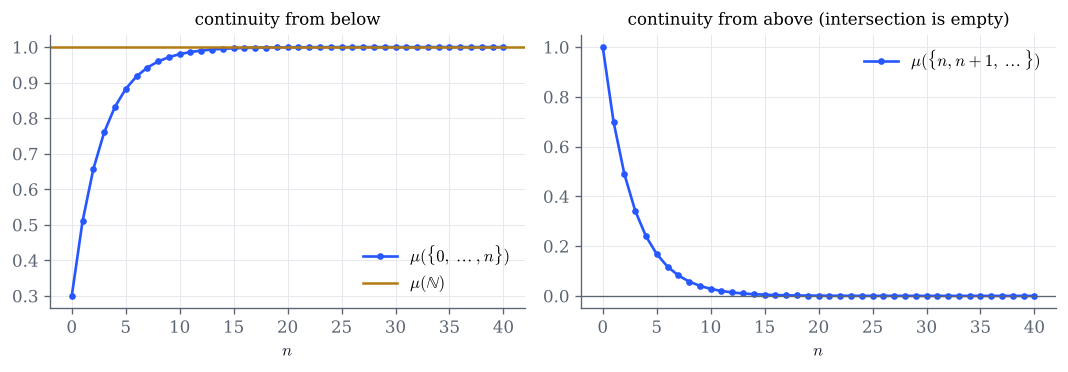

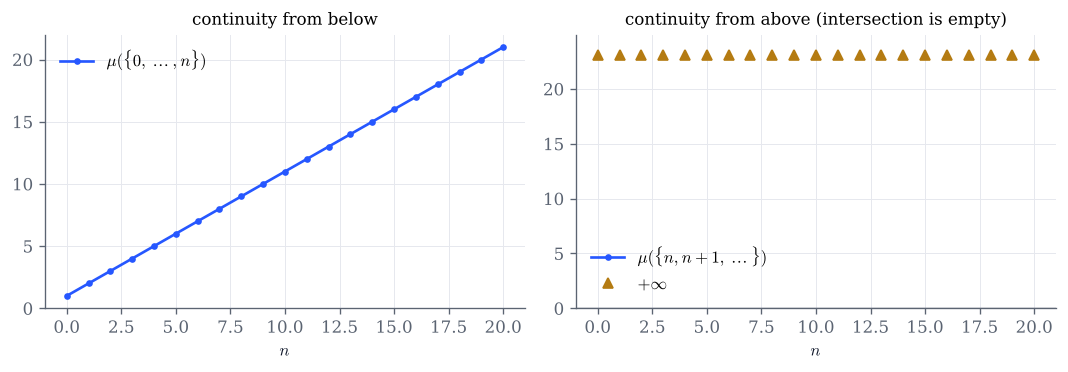

In [3]:
def make_measure(kind, param):
    if kind == "geometric":    # f(n) = (1 - q) q^n, a probability measure
        return DiscreteMeasure(lambda n: (1 - param) * param**n, total=1.0)
    if kind == "Poisson":      # f(n) = e^{-lam} lam^n / n!
        return DiscreteMeasure(lambda n: math.exp(-param + n * math.log(param) - math.lgamma(n + 1)), total=1.0)
    if kind == "1/(n+1)^2":    # finite, total mass pi^2/6
        return DiscreteMeasure(lambda n: 1.0 / (n + 1) ** 2, total=math.pi**2 / 6)
    return counting_measure()  # infinite on every infinite set


def continuity(kind="geometric", param=0.7, n_max=40):
    mu = make_measure(kind, param)
    n = np.arange(n_max + 1)
    up = np.array([mu(range(k + 1)) for k in n])
    down = np.array([mu(FinCofin.tail(k)) for k in n])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
    a1.plot(n, up, "o-", color=COBALT, ms=3, label=r"$\mu(\{0,\dots,n\})$")
    if math.isfinite(mu.total):
        a1.axhline(mu.total, color=GOLD, lw=1.5, label=r"$\mu(\mathbb{N})$")
    a1.set(xlabel="$n$", title="continuity from below")
    a1.legend()
    finite = np.isfinite(down)
    a2.plot(n[finite], down[finite], "o-", color=COBALT, ms=3, label=r"$\mu(\{n,n+1,\dots\})$")
    if (~finite).any():
        top = up.max() * 1.1
        a2.plot(n[~finite], np.full((~finite).sum(), top), "^", color=GOLD, label=r"$+\infty$")
        a2.set_ylim(0, top * 1.08)
    a2.axhline(0, color=GREY, lw=0.8)
    a2.set(xlabel="$n$", title="continuity from above (intersection is empty)")
    a2.legend()
    fig.tight_layout()
    plt.show()

continuity()
continuity("counting", 0.0, 20)

In [4]:
# Explore: param is q for the geometric law and lambda for the Poisson law (ignored otherwise).
interact(continuity,
         kind=Dropdown(options=["geometric", "Poisson", "1/(n+1)^2", "counting"], value="geometric", description="measure"),
         param=FloatSlider(value=0.7, min=0.05, max=0.95, step=0.05, continuous_update=False, description="q or λ"),
         n_max=IntSlider(value=40, min=5, max=200, step=5, continuous_update=False, description="n max"));

## 3. Lower and upper limits of a sequence of sets

On $X=\{0,\dots,11\}$, take a sequence of sets that is eventually periodic: a random start, then a block of
`period` sets repeated forever. A point is in $\liminf_nA_n$ if it belongs to all the $A_n$ from some $n$ on, and in
$\limsup_nA_n$ if it belongs to infinitely many (Remark after the definition). The panel shows which points lie
in which $A_n$ (filled squares), with the repeating block shaded. The printout checks the Proposition:
$\mu(\liminf A_n)\le\liminf\mu(A_n)\le\limsup\mu(A_n)\le\mu(\limsup A_n)$ for a random finite measure $\mu$.

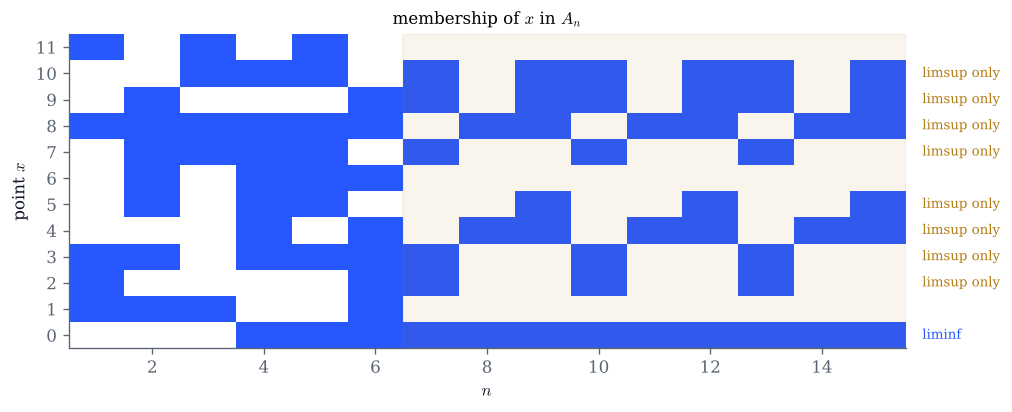

mu(liminf) = 0.104 <= liminf mu(A_n) = 2.708 <= limsup mu(A_n) = 5.735 <= mu(limsup) = 8.355


In [5]:
def sets_demo(n_start=6, period=3, density=0.6, seed=0):
    rng = np.random.default_rng(seed)
    X = range(12)
    seq = [frozenset(x for x in X if rng.random() < density) for _ in range(n_start + period)]
    lo, hi = liminf_limsup_periodic(seq, period)
    shown = seq + seq[-period:] * 2                    # two more periods, to see the repetition
    M = np.array([[x in A for A in shown] for x in X])
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.imshow(M, cmap=ListedColormap(["white", COBALT]), vmin=0, vmax=1, aspect="auto", origin="lower",
              extent=(0.5, len(shown) + 0.5, -0.5, 11.5))
    ax.axvspan(n_start + 0.5, len(shown) + 0.5, color=GOLD, alpha=0.08)
    for x in X:
        tag = "liminf" if x in lo else ("limsup only" if x in hi else "")
        ax.text(len(shown) + 0.8, x, tag, va="center", fontsize=8,
                color=COBALT if x in lo else (GOLD if x in hi else GREY))
    ax.set(xlabel="$n$", ylabel="point $x$", yticks=list(X), title="membership of $x$ in $A_n$")
    ax.grid(False)
    plt.show()
    mu = DiscreteMeasure({x: float(rng.exponential()) for x in X})
    vals = [mu(A) for A in seq[-period:]]
    print(f"mu(liminf) = {mu(lo):.3f} <= liminf mu(A_n) = {min(vals):.3f} "
          f"<= limsup mu(A_n) = {max(vals):.3f} <= mu(limsup) = {mu(hi):.3f}")

sets_demo()

In [6]:
interact(sets_demo,
         n_start=IntSlider(value=6, min=0, max=15, continuous_update=False, description="start"),
         period=IntSlider(value=3, min=1, max=6, continuous_update=False, description="period"),
         density=FloatSlider(value=0.6, min=0.1, max=0.95, step=0.05, continuous_update=False, description="density"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 4. Inclusion–exclusion

Poincaré's formula (Property 5) on random sets in a finite space with random weights. The partial sums
$P_k=\sum_{r\le k}(-1)^{r+1}S_r$ alternate around $\mu(\bigcup_iA_i)$ (Bonferroni's inequalities, Exercise 2.6)
and reach it at $k=n$. On the right, the matching problem: the probability that a random permutation of $n$
letters has no fixed point, $\sum_{r=0}^n(-1)^r/r!$, which converges to $e^{-1}$ extremely fast.

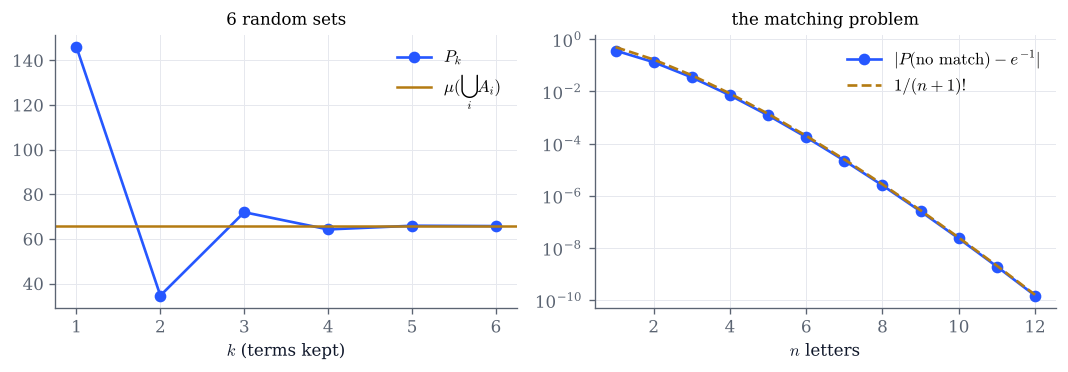

In [7]:
def inclusion_exclusion_demo(n_sets=6, density=0.35, seed=1):
    rng = np.random.default_rng(seed)
    X = range(60)
    mu = DiscreteMeasure({x: float(rng.exponential()) for x in X})
    sets = [frozenset(x for x in X if rng.random() < density) for _ in range(n_sets)]
    P = bonferroni_sums(mu, sets)
    U = mu(frozenset.union(*sets))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
    k = np.arange(1, n_sets + 1)
    a1.plot(k, P, "o-", color=COBALT, label="$P_k$")
    a1.axhline(U, color=GOLD, lw=1.5, label=r"$\mu(\bigcup_i A_i)$")
    a1.set(xlabel="$k$ (terms kept)", title=f"{n_sets} random sets")
    a1.legend()
    n = np.arange(1, 13)
    a2.semilogy(n, [abs(no_match_probability(m) - math.exp(-1)) for m in n], "o-", color=COBALT,
                label="$|P(\\mathrm{no\\ match}) - e^{-1}|$")
    a2.semilogy(n, [1 / math.factorial(m + 1) for m in n], "--", color=GOLD, label="$1/(n+1)!$")
    a2.set(xlabel="$n$ letters", title="the matching problem")
    a2.legend()
    fig.tight_layout()
    plt.show()

inclusion_exclusion_demo()

In [8]:
interact(inclusion_exclusion_demo,
         n_sets=IntSlider(value=6, min=2, max=12, continuous_update=False, description="sets"),
         density=FloatSlider(value=0.35, min=0.05, max=0.9, step=0.05, continuous_update=False, description="density"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 5. The Borel–Cantelli lemma

Independent events with $P(A_n)=n^{-\alpha}$: event $A_n$ occurs on a path when a uniform draw falls below
$n^{-\alpha}$. The panel shows the counts $N_n=\sum_{k\le n}\mathbb 1_{A_k}$ and their mean
$\sum_{k\le n}k^{-\alpha}$. For $\alpha\le1$ the series diverges and, by part 2, infinitely many $A_n$ occur
almost surely; for $\alpha>1$ it converges and, by part 1, only finitely many occur.

No finite simulation can show "infinitely often". What it can show is how fast the counts grow, and the printout
gives the exact probability of at least one occurrence in the last decade of the horizon,
$1-\prod_{N/10<k\le N}(1-k^{-\alpha})$, next to the simulated fraction. At $\alpha=1$ it is exactly $0.9$: one path in ten
stays flat over every decade, yet every path eventually moves again.

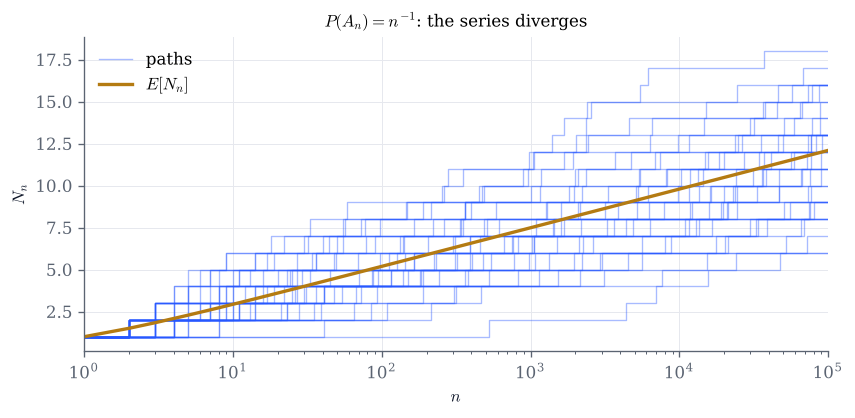

paths with an occurrence in (10000, 100000]: simulated 0.905 (of 200 paths), exact probability 0.9000
mean count 11.65, expected 12.09


In [9]:
def borel_cantelli(alpha=1.0, log10_horizon=5, n_paths=200, seed=2):
    N = 10**log10_horizon
    k = np.arange(1, N + 1, dtype=float)
    p = k**(-alpha)
    times = occurrence_times(p, n_paths=n_paths, seed=seed)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for i, t in enumerate(times[:40]):              # draw 40 paths; the statistics use all of them
        ax.step(np.r_[t, N], np.r_[np.arange(1, len(t) + 1), len(t)], where="post",
                color=COBALT, lw=0.8, alpha=0.4, label="paths" if i == 0 else None)
    grid = np.unique(np.logspace(0, log10_horizon, 300).astype(int))
    ax.plot(grid, np.cumsum(p)[grid - 1], color=GOLD, lw=2, label=r"$E[N_n]$")
    ax.set(xscale="log", xlim=(1, N), xlabel="$n$", ylabel="$N_n$",
           title=f"$P(A_n) = n^{{-{alpha:g}}}$: the series {'diverges' if alpha <= 1 else 'converges'}")
    ax.legend(loc="upper left")
    plt.show()
    late_sim = np.mean([np.any(t > N // 10) for t in times])
    late_exact = 1 - prob_no_event(p[N // 10:])
    print(f"paths with an occurrence in ({N // 10}, {N}]: simulated {late_sim:.3f} "
          f"(of {n_paths} paths), exact probability {late_exact:.4f}")
    print(f"mean count {np.mean([len(t) for t in times]):.2f}, expected {p.sum():.2f}")

borel_cantelli()

In [10]:
# Explore: try alpha = 0.5, 1, 1.1, 1.5, 2. Large horizons with many paths take a few seconds.
interact(borel_cantelli,
         alpha=FloatSlider(value=1.0, min=0.3, max=3.0, step=0.1, continuous_update=False, description="α"),
         log10_horizon=IntSlider(value=5, min=2, max=6, continuous_update=False, description="log10 N"),
         n_paths=IntSlider(value=200, min=10, max=1000, step=10, continuous_update=False, description="paths"),
         seed=IntSlider(value=2, min=0, max=100, continuous_update=False, description="seed"));

### Far beyond brute force

For $P(A_n)=1/n$ and $1/n^2$ the time of the next occurrence can be sampled directly. With $1/n$, given an
occurrence at $m$, there is none in $(m,j]$ with probability $\prod_{k=m+1}^{j}(1-\frac1k)=\frac mj$; with $1/n^2$
the product telescopes to $\frac{m(j+1)}{j(m+1)}$, which tends to $\frac m{m+1}$. This is
`occurrence_times_exact`, and it reaches $n=10^{12}$ in a fraction of a second. With $1/n$ the counts keep
growing like $\log n$; with $1/n^2$ the total count is finite, with mean $\pi^2/6$.

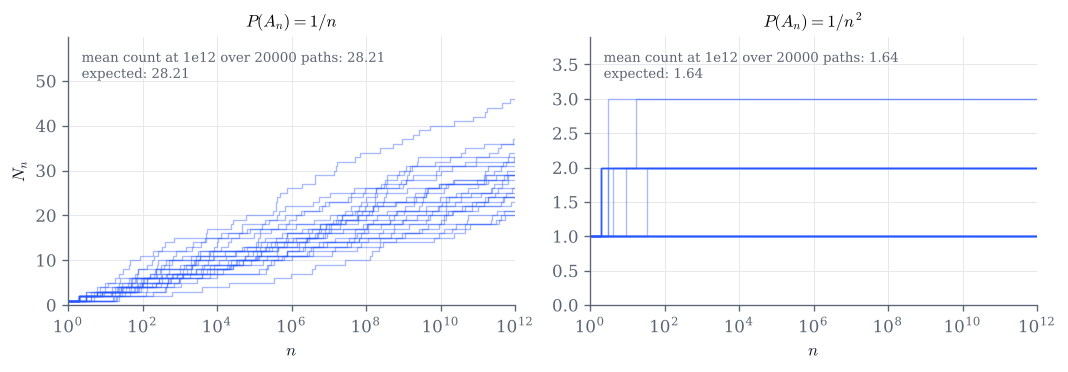

In [11]:
H = 1e12
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, kind, title in ((axes[0], "harmonic", "$P(A_n)=1/n$"), (axes[1], "square", "$P(A_n)=1/n^2$")):
    T = occurrence_times_exact(kind, H, n_paths=20_000, seed=5)
    for t in T[:25]:
        ax.step(np.r_[t, H], np.r_[np.arange(1, len(t) + 1), len(t)], where="post", color=COBALT, lw=0.8, alpha=0.4)
    counts = np.array([len(t) for t in T])
    ax.set(xscale="log", xlim=(1, H), ylim=(0, 1.3 * max(len(t) for t in T[:25])), xlabel="$n$", title=title)
    ax.text(0.03, 0.95, f"mean count at 1e12 over 20000 paths: {counts.mean():.2f}\n"
            f"expected: {math.log(H) + 0.5772 if kind == 'harmonic' else math.pi**2 / 6:.2f}",
            transform=ax.transAxes, va="top", fontsize=8, color=GREY)
axes[0].set_ylabel("$N_n$")
fig.tight_layout()
plt.show()

## Things to try

- In section 2, choose the measure `1/(n+1)^2`. Is it a probability measure? Which values does
  $\mu(\{n,n+1,\dots\})$ take, and how fast do they go to zero?
- In section 3, set the period to 1. What are $\liminf_nA_n$ and $\limsup_nA_n$ then, and why do they coincide?
- In section 5, compare $\alpha=1$ and $\alpha=1.1$ at the largest horizon. Could you tell from the picture which series
  diverges? (Exercise 2.9 makes this precise with $P(A_n)=1/(n\log n)$.)